# Bike-sharing demand: hourly counts

A bike-share desk publishes an hourly demand forecast so that rebalancing crews and dock stock can follow it. Demand is a count, its variance grows faster than its mean, and its daily shape is not the same on working days as on weekends: a two-peak commute profile on working days and a single afternoon hump otherwise. The decision is the predictive distribution of the hourly count, scored by its negative binomial log score, with the mean absolute error alongside.

The data are the UCI Bike Sharing hourly counts for Capital Bikeshare, Washington DC, 2011–2012: Fanaee-T, H. and Gama, J. (2013), "Event labeling combining ensemble detectors and background knowledge", *Progress in Artificial Intelligence* 2, 113–127. Source: UCI Machine Learning Repository, <https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset> (CC BY 4.0). The file `bike_sharing_hour.csv` is the archive's `hour.csv`, unchanged.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the predictive distribution of the hourly rental count |
| **Observed response** | `cnt`, casual plus registered rentals in the hour |
| **Estimand** | held-out negative binomial log score, and mean absolute error of the predicted mean |
| **Units** | nats per hour, lower is better; rentals per hour |
| **Sampling unit** | each row is one hour in Washington DC |
| **Dependence** | neighbouring hours share demand and weather; the split preserves calendar order |
| **Split and tuning** | consecutive hours; train through June 2012, tune on July–August 2012, score September–December 2012 |
| **Uncertainty** | fitted predictive densities are compared on one test period; no resampling intervals for score differences are computed |
| **Claim type** | predictive, conditional on the recorded weather and calendar variables; no causal effects are estimated |
| **Scope** | one city, two years; the test period lies inside the observed range of weather but after a growth year |
:::

In [1]:
import time
import warnings
from pathlib import Path

import altair as alt
from great_tables import GT
import lightgbm as lgb
import numpy as np
import polars as pl
import statsmodels.api as sm
from IPython.display import display
from pygam import PoissonGAM, f as pg_f, s as pg_s
from scipy.optimize import minimize_scalar
from scipy.special import gammaln
from statsmodels.gam.api import BSplines, GLMGam

import mboostrs as mb

alt.renderers.enable("svg")

path = Path("bike_sharing_hour.csv")
if not path.exists():
    path = Path("docs/book/case_studies/bike_sharing_hour.csv")
raw = pl.read_csv(path, try_parse_dates=True)
frame = raw.with_columns(
    pl.col("dteday").dt.ordinal_day().cast(pl.Float64).alias("doy"),
    pl.col("hr").cast(pl.Float64).alias("hour"),
    pl.col("weathersit").clip(1, 3).cast(pl.Utf8).cast(pl.Categorical).alias("weather"),
    pl.col("yr").cast(pl.Utf8).cast(pl.Categorical).alias("year"),
    (pl.col("temp") * 41).alias("temp_c"),
    (pl.col("hum") * 100).alias("humidity"),
    (pl.col("windspeed") * 67).alias("wind"),
)
d = pl.col("dteday")
train = frame.filter(d < pl.date(2012, 7, 1))
valid = frame.filter((d >= pl.date(2012, 7, 1)) & (d < pl.date(2012, 9, 1)))
fit_rows = frame.filter(d < pl.date(2012, 9, 1))
test = frame.filter(d >= pl.date(2012, 9, 1))
y_valid = valid["cnt"].to_numpy().astype(float)
y_test = test["cnt"].to_numpy().astype(float)
print(f"train {train.height}, tune {valid.height}, refit {fit_rows.height}, test {test.height} hours")

train 13003, tune 1488, refit 14491, test 2888 hours


In [2]:
def nb_score(y, mu, size):
    y = np.asarray(y, float)
    mu = np.asarray(mu, float)
    return float(-np.mean(gammaln(y + size) - gammaln(size) - gammaln(y + 1)
                          + size * np.log(size / (size + mu)) + y * np.log(mu / (size + mu))))


def poisson_score(y, mu):
    y = np.asarray(y, float)
    return float(-np.mean(y * np.log(mu) - mu - gammaln(y + 1)))


def size_mle(y, mu):
    r = minimize_scalar(lambda ls: nb_score(y, mu, np.exp(ls)), bounds=(-5, 10), method="bounded")
    return float(np.exp(r.x))


def glm_design(data):
    hr = data["hr"].to_numpy()
    wd = data["workingday"].to_numpy()
    cols = [(hr == h).astype(float) for h in range(1, 24)]
    cols += [((hr == h) & (wd == 1)).astype(float) for h in range(24)]
    weather = data["weathersit"].clip(1, 3).to_numpy()
    cols += [(weather == w).astype(float) for w in (2, 3)]
    cols += [(data["season"].to_numpy() == s).astype(float) for s in (2, 3, 4)]
    temp = data["temp_c"].to_numpy()
    cols += [data["yr"].to_numpy().astype(float), temp, temp**2, data["humidity"].to_numpy(),
             data["wind"].to_numpy(), data["holiday"].to_numpy().astype(float)]
    return sm.add_constant(np.column_stack(cols), has_constant="add")


rows = []


def add(method, family, score, mae, seconds, note=""):
    rows.append({"method": method, "family": family, "log_score": score, "mae": mae,
                 "seconds": round(seconds, 1), "note": note})

## Parametric baselines

The GLM has one dummy per hour, a separate working-day profile (24 hour × working-day dummies), weather, season, year, a quadratic in temperature, humidity, wind and holiday. That is the model a desk analyst writes first. The Poisson fit uses the same predictor formula and log link, with separately estimated coefficients. Its log score assesses the Poisson density on these counts.

In [3]:
start = time.time()
y_fit = fit_rows["cnt"].to_numpy().astype(float)
X_fit, X_test = glm_design(fit_rows), glm_design(test)
pois = sm.GLM(y_fit, X_fit, family=sm.families.Poisson()).fit()
nb = sm.NegativeBinomial(y_fit, X_fit).fit(start_params=np.append(pois.params, 0.1), disp=False,
                                           maxiter=200, method="newton")
alpha = float(nb.params[-1])
mu = nb.predict(X_test)
add("NB GLM", "NB", nb_score(y_test, mu, 1 / alpha), float(np.mean(np.abs(y_test - mu))), time.time() - start,
    f"size {1 / alpha:.2f}")
mu = pois.predict(X_test)
add("Poisson GLM", "Poisson", poisson_score(y_test, mu), float(np.mean(np.abs(y_test - mu))), 0.0)

## Spline GAMs outside mboostrs

`statsmodels` `GLMGam` takes the NB2 family at the GLM's dispersion, with ordinary B-splines (smooth piecewise curves; not the cyclic version, which joins the two ends of the range) in temperature, humidity, wind and day of year on top of the GLM's hour × working-day dummies; the penalty weight is chosen on the tuning months. `pygam` has no negative binomial family, so its Poisson GAM is scored twice: as Poisson, and as NB with a size parameter (the dispersion, with variance mu + mu^2/size) fitted to the tuning-month residuals.

In [4]:
start = time.time()
smooth_cols = ["temp_c", "humidity", "wind", "doy"]
lin_cols = list(range(0, 54)) + [58]  # const, hour, hour x workday, weather, season, yr, holiday


bounds = {c: (float(train[c].min()), float(train[c].max())) for c in smooth_cols}


def gam_parts(data):
    # BSplines refuses points outside its knots, so held-out values are clipped to the training range.
    X = glm_design(data)
    smooth = data.select(pl.col(c).clip(*bounds[c]) for c in smooth_cols).to_numpy()
    return X[:, lin_cols], smooth


def glmgam(train_rows, alpha_pen):
    Xl, Xs = gam_parts(train_rows)
    bs = BSplines(Xs, df=[6, 6, 6, 8], degree=[3, 3, 3, 3])
    model = GLMGam(train_rows["cnt"].to_numpy().astype(float), exog=Xl, smoother=bs,
                   alpha=[alpha_pen] * 4, family=sm.families.NegativeBinomial(alpha=alpha))
    return model.fit(), bs


def glmgam_predict(result, data):
    Xl, Xs = gam_parts(data)
    return result.predict(exog=Xl, exog_smooth=Xs)


tune = []
for pen in (0.1, 1.0, 10.0, 100.0):
    res, _ = glmgam(train, pen)
    tune.append((pen, nb_score(y_valid, glmgam_predict(res, valid), 1 / alpha)))
pen = min(tune, key=lambda t: t[1])[0]
res, _ = glmgam(fit_rows, pen)
mu = glmgam_predict(res, test)
add("GLMGam NB", "NB", nb_score(y_test, mu, 1 / alpha), float(np.mean(np.abs(y_test - mu))), time.time() - start,
    f"penalty {pen:g}")

start = time.time()
pg_cols = ["hr", "workingday", "weathersit", "season", "yr", "holiday", "temp_c", "humidity", "wind", "doy"]


def pg_X(data):
    return data.select(pg_cols).with_columns(pl.col("weathersit").clip(1, 3)).to_numpy().astype(float)


terms = (pg_s(0, n_splines=20, basis="cp", by=None) + pg_s(0, n_splines=20, basis="cp", by=1) + pg_f(2) + pg_f(3)
         + pg_f(4) + pg_f(5) + pg_s(6) + pg_s(7) + pg_s(8) + pg_s(9, basis="cp"))
gam_train = PoissonGAM(terms).gridsearch(pg_X(train), train["cnt"].to_numpy(), lam=np.logspace(-1, 3, 5),
                                         progress=False)
size_pg = size_mle(y_valid, gam_train.predict(pg_X(valid)))
gam = PoissonGAM(terms, lam=gam_train.lam).fit(pg_X(fit_rows), fit_rows["cnt"].to_numpy())
mu = gam.predict(pg_X(test))
seconds = time.time() - start
add("pygam Poisson", "Poisson", poisson_score(y_test, mu), float(np.mean(np.abs(y_test - mu))), seconds)
add("pygam, NB size on tune months", "NB (plug-in size)", nb_score(y_test, mu, size_pg),
    float(np.mean(np.abs(y_test - mu))), 0.0, f"size {size_pg:.2f}")

## mboostrs gamboost, negative binomial

Two formulas. The additive one has a single cyclic hour profile shared by all days. The second adds `bbs(hour, cyclic=True, by=workingday)`, the working-day difference curve. A factor `by=` with `cyclic=True` is not accepted by the API, a current limitation, so the 0/1 column `workingday` is used as a numeric multiplier, which fits the same difference for a two-level factor. Both are boosted at `nu=0.1` with a cap of 3,000 steps; the step count is chosen on the tuning months, then the model is refit on everything before September 2012.

In [5]:
base = ("cnt ~ bols(year) + bbs(hour, cyclic=True, knots=23, df=4)"
        " + bbs(temp_c, df=4) + bbs(humidity, df=4) + bbs(wind, df=4) + bols(weather)"
        " + bbs(doy, cyclic=True, df=4) + bols(holiday)")
formulas = {
    "gamboost NB, additive": base,
    "gamboost NB, hour x working day": base + " + bbs(hour, cyclic=True, knots=23, df=4, by=workingday)",
}
cap, nu = 3000, 0.1
fits, curves = {}, {}
for method, formula in formulas.items():
    start = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        tuned = mb.gamboost(formula, train, family=mb.NBinomial(), control=mb.boost_control(cap, nu))
    curve = []
    for k in range(300, cap + 1, 300):
        mk = tuned.with_mstop(k)
        mu = np.asarray(mk.predict(valid, type="response"))
        curve.append((k, nb_score(y_valid, mu, mk.size)))
    curves[method] = curve
    k = min(curve, key=lambda c: c[1])[0]
    with warnings.catch_warnings(record=True) as caught_refit:
        warnings.simplefilter("always")
        final = mb.gamboost(formula, fit_rows, family=mb.NBinomial(), control=mb.boost_control(k, nu))
    fits[method] = final
    mu = np.asarray(final.predict(test, type="response"))
    drift = [str(w.message)[:90] for w in caught + caught_refit if "penalty" in str(w.message)]
    add(method, "NB", nb_score(y_test, mu, final.size), float(np.mean(np.abs(y_test - mu))),
        time.time() - start, f"mstop {k}{' (at cap)' if k == cap else ''}, size {final.size:.2f}")
    print(method, "| mstop", k, "| warnings:", drift[:1])

gamboost NB, additive | mstop 3000 | warnings: ['boosting has undone much of the penalty of 1 learner(s): bbs(hour): 11.6 of 23 df after 22']


gamboost NB, hour x working day | mstop 3000 | warnings: ['boosting has undone much of the penalty of 2 learner(s): bbs(hour): 10.3 of 23 df after 12']


In [6]:
names = fits["gamboost NB, hour x working day"].base_learner_names()
print(names)
display(fits["gamboost NB, hour x working day"].penalty_drift())
try:
    print(mb.same_family_gap(fits["gamboost NB, hour x working day"]))
except Exception as exc:
    print(type(exc).__name__, ":", str(exc)[:300])

['bols(year)', 'hour (bbs)', 'temp_c', 'humidity', 'wind', 'bols(weather)', 'doy', 'holiday', 'hour (bbs, by=workingday)']


learner,selections,single_step_df,boosted_df,unpenalized_df,drift_share
str,i64,f64,f64,f64,f64
"""bols(year)""",16,2.0,1.629396,2.0,0.0
"""bbs(hour)""",1235,3.100327,10.352912,23.0,0.364457
"""bbs(temp_c)""",71,3.37058,5.242685,24.0,0.090749
"""bbs(humidity)""",96,3.362242,5.685841,23.0,0.118323
"""bbs(wind)""",16,3.365175,3.156487,23.0,0.0
"""brandom(bols(weather))""",7,3.0,1.565109,3.0,0.0
"""bbs(doy)""",328,3.00424,7.936499,21.0,0.274079
"""bols(holiday)""",1,2.0,0.2,2.0,0.0
"""bbs(hour)""",1230,3.100435,10.34453,23.0,0.364033


No same-family GLM comparison for NBinomial: this is a gamboost fit. A same-family GLM is comparable only when it uses the same basis, and a smooth basis is not the linear specification this check fits. Boost logLik at mstop=3000 is -70559.5233. The selected step was not changed.


## Accuracy reference: LightGBM

A LightGBM gradient-boosted tree model (a Poisson objective) on the raw features, with boosting iterations (rounds) chosen on the tuning months, gives the accuracy a flexible learner reaches without any structure. It has no dispersion of its own; its NB score uses a size fitted on the tuning months.

In [7]:
start = time.time()
feat = ["hr", "workingday", "holiday", "weathersit", "temp_c", "atemp", "humidity", "wind", "doy", "yr",
        "season", "weekday"]


def lgb_X(data):
    return data.select(feat).to_numpy().astype(float)


params = dict(objective="poisson", learning_rate=0.05, num_leaves=31, min_data_in_leaf=20, verbose=-1, seed=1)
booster = lgb.train(params, lgb.Dataset(lgb_X(train), train["cnt"].to_numpy()), num_boost_round=2000)
best = min(((k, poisson_score(y_valid, booster.predict(lgb_X(valid), num_iteration=k)))
            for k in range(100, 2001, 100)), key=lambda t: t[1])
size_l = size_mle(y_valid, booster.predict(lgb_X(valid), num_iteration=best[0]))
booster = lgb.train(params, lgb.Dataset(lgb_X(fit_rows), fit_rows["cnt"].to_numpy()), num_boost_round=best[0])
mu = booster.predict(lgb_X(test))
add("LightGBM (reference)", "NB (plug-in size)", nb_score(y_test, mu, size_l), float(np.mean(np.abs(y_test - mu))),
    time.time() - start, f"{best[0]} rounds, size {size_l:.2f}")
summary = pl.DataFrame(rows).sort("log_score")


In [8]:
# Bold cells survive PDF export; colour alone would not identify the best value.
comparison = (GT(summary, rowname_col="method")
    .tab_header(title="Hourly bike demand: held-out density and mean predictions",
                subtitle="September–December 2012; lower log score and MAE are better")
    .tab_stubhead("Method")
    .tab_spanner("Predictive accuracy", columns=["log_score", "mae"])
    .cols_label({"family": "Density", "log_score": "Log score (nats/hour)",
                 "mae": "MAE (rentals/hour)", "seconds": "Fit and tune (s)", "note": "Fit"})
    .fmt_number(columns="seconds", decimals=1)
    .tab_source_note("Log score is mean negative log probability under each fitted density; "
                     "MAE is mean absolute error of the predicted expected count.")
    .tab_source_note("One contiguous four-month test period; no resampling intervals are reported. "
                     "Bold marks the smallest displayed value; no inferential ranking is made.")
    .tab_source_note("Times cover fitting and tuning in this run; method-specific threading and "
                     "tuning procedures differ, so these are not controlled speed comparisons.")
    .tab_source_note("Source: UCI Bike Sharing hour.csv (bike_sharing_hour.csv), 2011–2012."))
for column, digits in [("log_score", 3), ("mae", 1)]:
    best = format(summary[column].min(), f".{digits}f")
    def cell(value, best=best, digits=digits):
        shown = format(value, f".{digits}f")
        return f"<strong>{shown}</strong>" if shown == best else shown
    comparison = comparison.fmt(cell, columns=column)
display(comparison)


GT(_tbl_data=shape: (8, 6)
┌──────────────────────┬───────────────────┬───────────┬───────────┬─────────┬─────────────────────┐
│ method               ┆ family            ┆ log_score ┆ mae       ┆ seconds ┆ note                │
│ ---                  ┆ ---               ┆ ---       ┆ ---       ┆ ---     ┆ ---                 │
│ str                  ┆ str               ┆ f64       ┆ f64       ┆ f64     ┆ str                 │
╞══════════════════════╪═══════════════════╪═══════════╪═══════════╪═════════╪═════════════════════╡
│ LightGBM (reference) ┆ NB (plug-in size) ┆ 5.256864  ┆ 41.481188 ┆ 17.7    ┆ 700 rounds, size    │
│                      ┆                   ┆           ┆           ┆         ┆ 18.38               │
│ NB GLM               ┆ NB                ┆ 5.275842  ┆ 43.319394 ┆ 0.6     ┆ size 11.41          │
│ GLMGam NB            ┆ NB                ┆ 5.283868  ┆ 43.8258   ┆ 3.9     ┆ penalty 100         │
│ gamboost NB, hour x  ┆ NB                ┆ 5.330374  ┆ 45.180636 ┆ 15.8    ┆ mstop 3000 (at      │
│ working da…          ┆                   ┆           ┆           ┆         ┆ cap), size 11.4…    │
│ pygam, NB size on    ┆ NB (plug-in size) ┆ 5.366994  ┆ 42.60844  ┆ 0.0     ┆ size 14.96          │
│ tune months          ┆                   ┆           ┆           ┆         ┆                     │
│ gamboost NB,         ┆ NB                ┆ 5.728197  ┆ 79.012707 ┆ 14.8    ┆ mstop 3000 (at      │
│ additive             ┆                   ┆           ┆           ┆         ┆ cap), size 3.75     │
│ pygam Poisson        ┆ Poisson           ┆ 11.713055 ┆ 42.60844  ┆ 1.8     ┆                     │
│ Poisson GLM          ┆ Poisson           ┆ 11.971025 ┆ 43.33251  ┆ 0.0     ┆                     │
└──────────────────────┴───────────────────┴───────────┴───────────┴─────────┴─────────────────────┘, _body=<great_tables._gt_data.Body object at 0x11b5454c0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='family', type=<ColInfoTypeEnum.default: 1>, column_label='Density', column_align='left', column_width=None), ColInfo(var='log_score', type=<ColInfoTypeEnum.default: 1>, column_label='Log score (nats/hour)', column_align='right', column_width=None), ColInfo(var='mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE (rentals/hour)', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='Fit and tune (s)', column_align='right', column_width=None), ColInfo(var='note', type=<ColInfoTypeEnum.default: 1>, column_label='Fit', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11be225a0>, _spanners=Spanners([SpannerInfo(spanner_id='Predictive accuracy', spanner_level=0, spanner_label='Predictive accuracy', spanner_units=None, spanner_pattern=None, vars=['log_score', 'mae'], built=None)]), _heading=Heading(title='Hourly bike demand: held-out density and mean predictions', subtitle='September–December 2012; lower log score and MAE are better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11be230e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11be82a50>, _source_notes=['Log score is mean negative log probability under each fitted density; MAE is mean absolute error of the predicted expected count.', 'One contiguous four-month test period; no resampling intervals are reported. Bold marks the smallest displayed value; no inferential ranking is made.', 'Times cover fitting and tuning in this run; method-specific threading and tuning procedures differ, so these are not controlled speed comparisons.', 'Source: UCI Bike Sharing hour.csv (bike_sharing_hour.csv), 2011–2012.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11be82240>, _formats=[<great_tables._gt_data.FormatInfo object at 0x11b365a30>, <great_tables._gt_data.Form

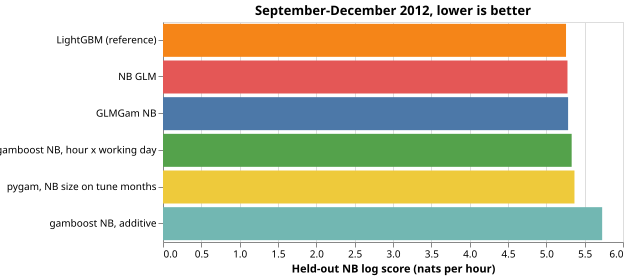

In [9]:
scored = summary.filter(pl.col("family") != "Poisson")
alt.Chart(scored).mark_bar().encode(
    x=alt.X("log_score:Q", title="Held-out NB log score (nats per hour)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(width=460, height=220, title="September-December 2012, lower is better")

partial_effects keys: ['bols(weather)', 'bols(year)', 'doy', 'holiday', 'hour (bbs)', 'hour (bbs, by=workingday)', 'humidity', 'temp_c', 'wind']


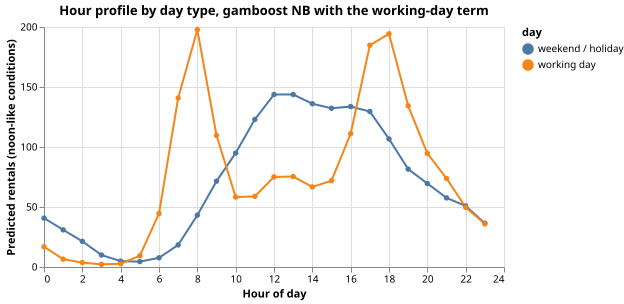

In [10]:
model = fits["gamboost NB, hour x working day"]
print("partial_effects keys:", sorted(model.partial_effects()))
# Hour profile read off predictions, so it does not depend on how the learners are named.
ref = fit_rows.filter((pl.col("hr") == 12) & (pl.col("workingday") == 1)).head(1)
grid = pl.concat([ref.with_columns(pl.lit(float(h)).alias("hour"), pl.lit(h).alias("hr"),
                                   pl.lit(w).cast(ref["workingday"].dtype).alias("workingday"))
                  for h in range(24) for w in (0, 1)])
profile = grid.select("hour", pl.when(pl.col("workingday") == 1).then(pl.lit("working day"))
                      .otherwise(pl.lit("weekend / holiday")).alias("day")).with_columns(
    pl.Series("mean", np.asarray(model.predict(grid, type="response"))))
alt.Chart(profile).mark_line(point=True).encode(
    x=alt.X("hour:Q", title="Hour of day"), y=alt.Y("mean:Q", title="Predicted rentals (noon-like conditions)"),
    color="day:N",
).properties(width=460, height=240, title="Hour profile by day type, gamboost NB with the working-day term")

In [11]:
get = lambda m: summary.filter(pl.col("method") == m).row(0, named=True)
glm, gg, gi, lg = get("NB GLM"), get("GLMGam NB"), get("gamboost NB, hour x working day"), get("LightGBM (reference)")
ga = get("gamboost NB, additive")
desk_text = (
    f"Publish the negative binomial GLM with the hour x working-day profile (or its GLMGam version, which scores "
    f"{gg['log_score']:.3f} against {glm['log_score']:.3f} nats and is not worth a second model). It scores "
    f"{glm['log_score']:.3f} nats per hour with an MAE of {glm['mae']:.1f} rentals. LightGBM has the smallest observed log score among these candidates "
    f"here at {lg['log_score']:.3f} nats and {lg['mae']:.1f} MAE, a gap too small to give up a model whose terms a desk "
    f"can read. The gamboost fit with the working-day term scores {gi['log_score']:.3f} / {gi['mae']:.1f}; the additive "
    f"one {ga['log_score']:.3f} / {ga['mae']:.1f}. The working-day difference "
    f"improves the held-out score on this split. The Poisson GLM uses "
    f"the same predictor formula and loses {get('Poisson GLM')['log_score'] - glm['log_score']:.1f} nats per hour. This is one test period, without resampling intervals for score differences."
)
print(desk_text)

Publish the negative binomial GLM with the hour x working-day profile (or its GLMGam version, which scores 5.284 against 5.276 nats and is not worth a second model). It scores 5.276 nats per hour with an MAE of 43.3 rentals. LightGBM has the smallest observed log score among these candidates here at 5.257 nats and 41.5 MAE, a gap too small to give up a model whose terms a desk can read. The gamboost fit with the working-day term scores 5.330 / 45.2; the additive one 5.728 / 79.0. The working-day difference improves the held-out score on this split. The Poisson GLM uses the same predictor formula and loses 6.7 nats per hour. This is one test period, without resampling intervals for score differences.


## Forecast decision

{eval}`desk_text`

## Fit diagnostics

- **Learner labels.** `base_learner_names()` distinguishes the hour profile from its working-day difference, so each partial effect and extraction entry (an item in the fitted component list) can be selected separately.
- **Penalty drift.** Repeated selections increase the accumulated flexibility beyond the learner's one-step `df=4` (its effective degrees of freedom for a single update; 4 by default for `bbs`). Choose the stopping point on the tuning months; the penalty-drift report describes the selected terms' accumulated flexibility.
- **Linear comparison.** `same_family_gap` currently supports linear boosts only, so it is not applied to the spline fits here. This additive fit's comparison with a negative-binomial GLM is the comparison in "Parametric baselines".
- **Step length.** A large fixed `nu` can make a calibrated negative-binomial path rise after its best training step. The fit reports material backslide (a rise in risk after the minimum) and the iteration of the minimum. Use a smaller `nu` or `boost_control(step="line_search")`; the main fits here retain `nu=0.1`.
